<a href="https://colab.research.google.com/github/ishwarikale44-byte/LP-3-Practical/blob/main/Copy_of_ML4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Loaded Successfully!
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 

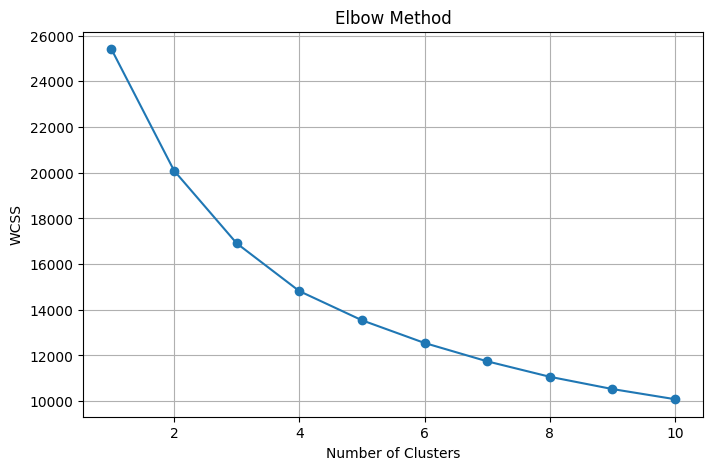


Cluster Results:
   Cluster
0        1
1        2
2        1
3        1
4        1
5        1
6        1
7        1
8        1
9        0

Number of Records in Each Cluster:
Cluster
1    1183
2     906
0     734
Name: count, dtype: int64


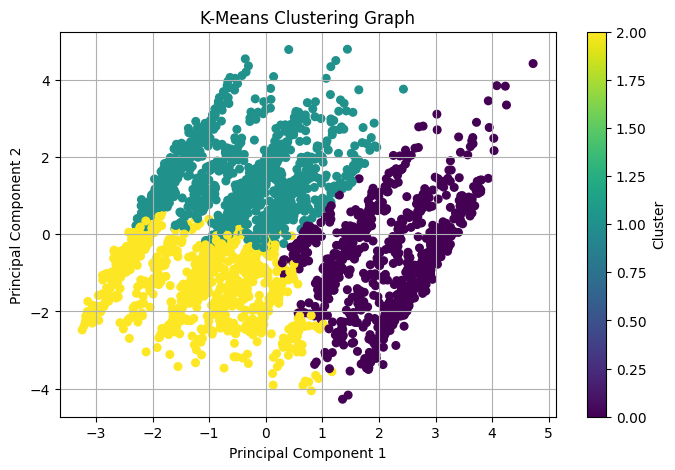


Experiment Completed Successfully!
K-Means Clustering Applied Successfully.
Number of Clusters = 3


In [ ]:
# K-Means Clustering

# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


# 2. Download and Load Dataset

url = "https://huggingface.co/datasets/adityaswami89/Salesdata/resolve/main/sales_data_sample.csv"

df = pd.read_csv(url, encoding='latin1')

print("Dataset Loaded Successfully!")
print(df.head())

print("\nDataset Shape:", df.shape)


# 3. Select Numerical Data

data = df.select_dtypes(include=np.number)

data = data.dropna(axis=1, how='all')

data = data.fillna(data.median())

data = data.loc[:, data.nunique() > 1]

print("\nSelected Data:")
print(data.head())


# 4. Normalize Data

scaler = StandardScaler()

scaled_data = scaler.fit_transform(data)


# 5. Elbow Method

wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_data)

    wcss.append(kmeans.inertia_)


# 6. Elbow Graph

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")

plt.grid()
plt.show()


# 7. Apply K-Means

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(scaled_data)

df['Cluster'] = clusters

print("\nCluster Results:")
print(df[['Cluster']].head(10))


# 8. Cluster Count

print("\nNumber of Records in Each Cluster:")
print(df['Cluster'].value_counts())


# 9. PCA for Graph Visualization

pca = PCA(n_components=2)

reduced_data = pca.fit_transform(scaled_data)


# 10. Cluster Graph

plt.figure(figsize=(8, 5))

plt.scatter(
    reduced_data[:, 0],
    reduced_data[:, 1],
    c=clusters,
    cmap='viridis',
    s=30
)

plt.title("K-Means Clustering Graph")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(label="Cluster")

plt.grid()
plt.show()


# 11. Final Result

print("\nExperiment Completed Successfully!")

print("K-Means Clustering Applied Successfully.")

print("Number of Clusters = 3")